# Task 4 · Pretrained embeddings + MLP
A frozen DINOv2-small (a vision transformer with 22M parameters, trained on 142M images without labels) turns each
image, upsampled from 32×32 to 112×112, into a 384-number embedding once; a small MLP learns the classes from these
embeddings. It is compared with the Task 1 MLP and CNN.

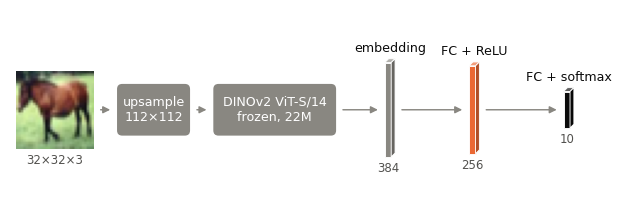

In [1]:
from hw3 import *
from sklearn.manifold import TSNE

B = json.load(open(BEST))
X, Y, Xte, Yte = cifar()
diagram('arch_dino', [[('upsample\n112×112', '', MUTED), ('DINOv2 ViT-S/14\nfrozen, 22M', '', MUTED),
                       (384, 'embedding', MUTED), (256, 'FC + ReLU', COL['mlp']), (10, 'FC + softmax', INK)]],
        X[int((Y == 7).nonzero()[0])])

In [2]:
if not os.path.exists(DINO):
    from transformers import Dinov2Model
    vit = Dinov2Model.from_pretrained('facebook/dinov2-small').eval()
    m, s = torch.tensor([.485, .456, .406]).view(1, 3, 1, 1), torch.tensor([.229, .224, .225]).view(1, 3, 1, 1)
    embed = lambda X: torch.cat([vit(pixel_values=(F.interpolate(x / 255, 112, mode='bicubic') - m) / s).pooler_output
                                 for x in X.split(250)])
    t = time.perf_counter()
    with torch.inference_mode():
        Z = dict(train=embed(X), test=embed(Xte))
    torch.save(Z | dict(seconds=time.perf_counter() - t), DINO)
Z = torch.load(DINO)
Z['train'].shape, Z['seconds'] / 60

(torch.Size([50000, 384]), 26.22633841833255)

In [3]:
S = {B['mlp']['key']: dict(model=partial(MLP, B['mlp']['arch']), lr=B['mlp']['lr']),
     B['cnn']['key']: dict(model=partial(CNN, B['cnn']['arch']), lr=B['cnn']['lr']),
     'dino_mlp': dict(model=partial(MLP, (256,), .2, 384), lr=1e-3, epochs=20, kind='dino')}
G = dict(zip(['MLP', 'CNN', 'DINOv2 + MLP'], zip(S, [COL[c] for c in ('mlp', 'cnn', 'dino')])))
R = cv(S)
P = pd.DataFrame({k: profile(S[k]['model'], S[k].get('kind', 'pixels')) for k in S}).T
P['val'], P['test'] = ([ms(last(R[k], m)) for k in S] for m in ('val_acc', 'test_acc'))
P.set_axis(list(G))

,params,weights,adam,acts,epoch,val,test
MLP,3805450.0,14.516640,43.549919,2.375000,11.479469,56.7 (0.4),56.4 (0.3)
CNN,620810.0,2.368202,7.104607,78.628418,35.924813,81.4 (0.2),81.0 (0.3)
DINOv2 + MLP,101130.0,0.385780,1.157341,0.562500,0.965844,90.5 (0.4),90.1 (0.1)


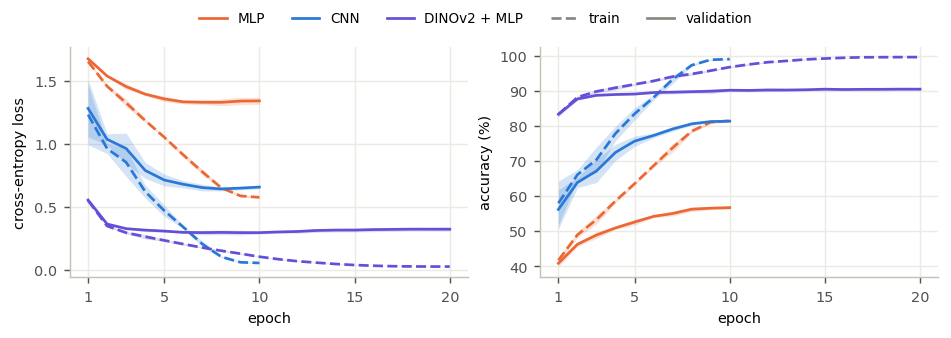

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
curves({k: (R[n], c) for k, (n, c) in G.items()}, axes)
for ax in axes:
    ax.set_xticks([1, 5, 10, 15, 20])
save(fig, 'dino_curves')

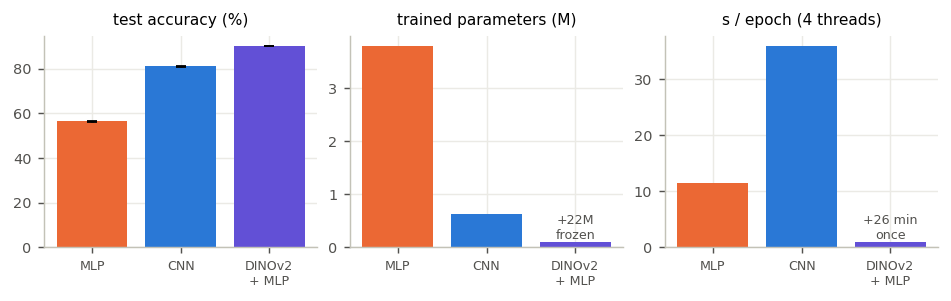

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2))
names, colors = ['MLP', 'CNN', 'DINOv2\n+ MLP'], [c for _, c in G.values()]
acc = np.array([last(R[n], 'test_acc') for n in S]) * 100
axes[0].bar(names, acc.mean(1), yerr=acc.std(1, ddof=1), capsize=3, color=colors)
axes[1].bar(names, P.params / 1e6, color=colors)
axes[1].text(2, P.params.iloc[2] / 1e6, '+22M\nfrozen', ha='center', va='bottom', fontsize=7, color=TEXT)
axes[2].bar(names, P.epoch, color=colors)
axes[2].text(2, P.epoch.iloc[2], f"+{Z['seconds'] / 60:.0f} min\nonce", ha='center', va='bottom', fontsize=7, color=TEXT)
for ax, t in zip(axes, ('test accuracy (%)', 'trained parameters (M)', 's / epoch (4 threads)')):
    ax.set_title(t)
    ax.tick_params(axis='x', labelsize=7)
save(fig, 'dino_compare')

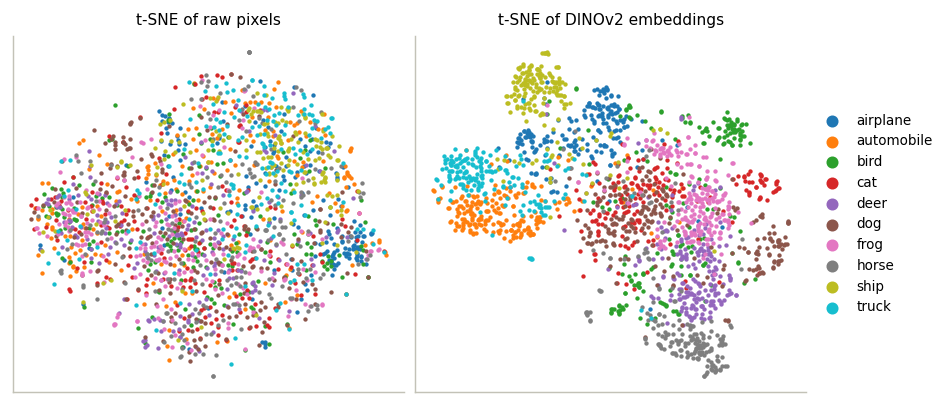

In [6]:
sub = torch.randperm(len(Yte), generator=torch.Generator().manual_seed(SEED))[:2000]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3))
for ax, (t, e) in zip(axes, {'raw pixels': prep(Xte[sub]).flatten(1), 'DINOv2 embeddings': Z['test'][sub]}.items()):
    p = TSNE(2, init='pca', random_state=SEED).fit_transform(e.numpy())
    for c in range(10):
        ax.scatter(*p[(Yte[sub] == c).numpy()].T, s=2, color=plt.cm.tab10(c), label=CLASSES[c])
    ax.set(title=f't-SNE of {t}', xticks=[], yticks=[])
axes[1].legend(markerscale=4, loc='center left', bbox_to_anchor=(1, .5))
save(fig, 'tsne')

In [7]:
tex('t4', dinoMinutes=f"{Z['seconds'] / 60:.0f}", dinoTest=P.test['dino_mlp'], dinoParams=f"{P.params['dino_mlp'] / 1e3:.0f}",
    dinoEpoch=f"{P.epoch['dino_mlp']:.1f}")